# CIFAR-10 image classification with a Selective-Kernel-style CNN ensemble

## Architecture overview

The network is a sequence of intermediate blocks followed by an output block.

**Intermediate block:** receives a feature map `x` with `c` channels and outputs the feature map $x' = \sum_{l=1}^{L} a_l \, C_l(x)$, the sum of the branch outputs weighted by $a_l$, where:
- `L` independent convolutional layers `C_1, ..., C_L` each receive the same input `x` (they run side by side, not one after another)
- all `C_l(x)` have the same shape
- `m = GAP(x) ∈ R^c` is the global average pooling of the input (the mean of each channel over all pixels)
- `a = FC(m) ∈ R^L` comes from a single fully connected layer with `L` output units
- the weighted sum gives `x'` with the same spatial shape as each `C_l(x)`

**Output block:** global average pooling of the input, followed by one fully connected layer that produces 10 logits (one score per class).

This pattern is a simplified variant of *Selective Kernel Networks* (SKNet, Li et al., CVPR 2019), in which a block learns how much to use each of several parallel convolutions. Compared with the original SKNet:
- the attention weights `a_l` are one scalar per branch (not one per channel)
- `m` is computed from the input `x` directly (not from the sum of the branch outputs)
- there is no softmax normalisation on `a`
- the weights come from a single fully connected layer (no bottleneck layer)

## Notebook outline

1. Imports, data loaders and augmentation (Sections 1 to 3)
2. Intermediate block, the full network (called `SKNet` here) and the run configurations (Sections 4 and 5)
3. Weight averaging (EMA) and the training loop (Sections 6 and 7)
4. `basic_mode`, the switch that turns the network back into the plain block sequence, and its unit test (Sections 8 and 12)
5. Best single model, the `I2` configuration: training curves and final accuracy (Sections 9 and 10), evaluation with horizontal-flip averaging (Section 11)
6. Ensemble of four models: 98.42% test accuracy without flip averaging, 98.37% with it (Section 13)


## 1. Imports and environment

In [1]:
import os
import math
import time
import copy
import random
from dataclasses import dataclass, field
from typing import List, Optional, Dict

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# cuDNN benchmark mode picks the fastest convolution algorithm for the fixed 32x32 input.
# It also makes runs not bit-for-bit repeatable, even with fixed seeds.
torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Using device: cuda
GPU: Tesla T4


## 2. CIFAR-10 data loaders

Training augments each image (listed below) and mixes some batches (CutMix and MixUp, Sections 3 and 7).

**Per-image augmentations** (applied to each image before it becomes a tensor, except Cutout, which runs after normalisation):

- `RandomCrop(32, padding=4, padding_mode='reflect')`: pads each side by 4 mirrored pixels and takes a random 32x32 crop, so objects appear at slightly shifted positions.
- `RandomHorizontalFlip(p=0.5)`: mirrors half of the images left to right.
- `TrivialAugmentWide()`: applies one randomly chosen geometric or photometric change (rotation, shear, contrast, brightness, sharpness and others) at a random strength.
- `ToTensor()` and `Normalize(CIFAR10_MEAN, CIFAR10_STD)`: converts to a float tensor and standardises each channel with the dataset mean and standard deviation.
- `Cutout(length=16)`: after normalisation, sets one 16x16 square at a random position to zero, which is the dataset mean colour.


In [2]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)


class Cutout:
    """Erases a random square region from a tensor image."""
    def __init__(self, n_holes: int = 1, length: int = 16):
        self.n_holes = n_holes
        self.length = length

    def __call__(self, img: torch.Tensor) -> torch.Tensor:
        h, w = img.shape[1], img.shape[2]
        mask = torch.ones((h, w), dtype=img.dtype)
        for _ in range(self.n_holes):
            y = int(torch.randint(0, h, (1,)).item())
            x = int(torch.randint(0, w, (1,)).item())
            y1 = max(0, y - self.length // 2)
            y2 = min(h, y + self.length // 2)
            x1 = max(0, x - self.length // 2)
            x2 = min(w, x + self.length // 2)
            mask[y1:y2, x1:x2] = 0.
        return img * mask.unsqueeze(0)


train_transform = T.Compose([
    T.RandomCrop(32, padding=4, padding_mode='reflect'),
    T.RandomHorizontalFlip(p=0.5),
    T.TrivialAugmentWide(),
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    Cutout(n_holes=1, length=16),
])

test_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

BATCH_SIZE = 128

# Loaders are filled by _init_default_loaders().
train_dataset = test_dataset = train_loader = test_loader = None


def _init_default_loaders(data_root: str = './data', num_workers: int = 2):
    """Populate the module-level train_loader / test_loader."""
    global train_dataset, test_dataset, train_loader, test_loader
    train_dataset = torchvision.datasets.CIFAR10(
        root=data_root, train=True, download=True, transform=train_transform)
    test_dataset = torchvision.datasets.CIFAR10(
        root=data_root, train=False, download=True, transform=test_transform)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=num_workers, pin_memory=True, drop_last=True,
                              persistent_workers=False)
    test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False,
                              num_workers=num_workers, pin_memory=True,
                              persistent_workers=False)
    print(f'Train examples: {len(train_dataset)}, test examples: {len(test_dataset)}')
    print(f'Batches per epoch (train): {len(train_loader)}')

In [3]:
_init_default_loaders()

100%|██████████| 170M/170M [00:13<00:00, 12.3MB/s]


Train examples: 50000, test examples: 10000
Batches per epoch (train): 390


### Preview a batch

Batch shape: torch.Size([128, 3, 32, 32]), labels shape: torch.Size([128])


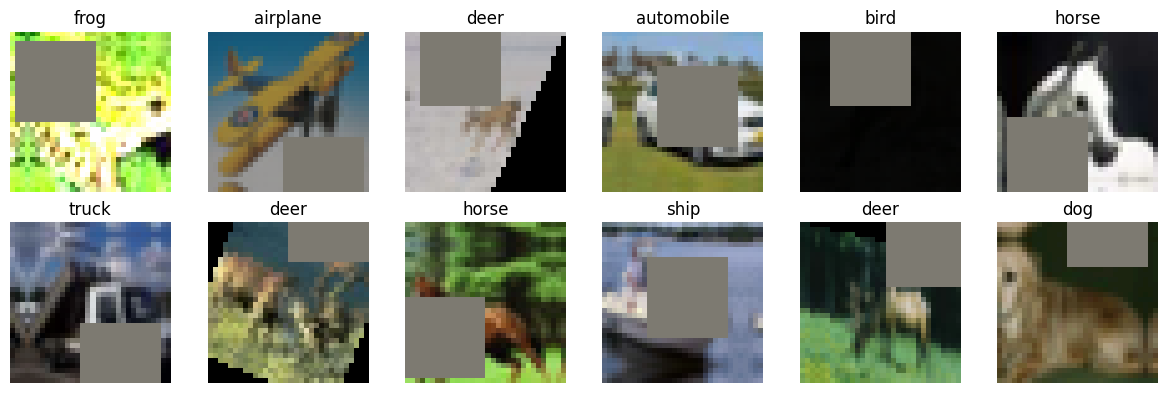

In [4]:
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

x_batch, y_batch = next(iter(train_loader))
print(f'Batch shape: {x_batch.shape}, labels shape: {y_batch.shape}')

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    img = x_batch[i].numpy().transpose(1, 2, 0)
    # de-normalise for visualisation
    img = img * np.array(CIFAR10_STD) + np.array(CIFAR10_MEAN)
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.set_title(CLASSES[y_batch[i].item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. CutMix (main batch-level augmentation)

Yun et al., 'CutMix: Regularization Strategy to Train Strong Classifiers with Localizable Features' (ICCV 2019). With probability `cutmix_prob` a batch is mixed as follows. `λ` is drawn from `Beta(α, α)`, a random rectangle covering a fraction `1-λ` of the image is chosen, and the same rectangle taken from another image of the batch is pasted into each image (the partner is chosen by shuffling the batch). The target becomes a mixture of both labels: the loss is `λ` times the loss for the first label plus `1-λ` times the loss for the second label.


In [5]:
def _rand_bbox(size, lam):
    _, _, H, W = size
    cut_rat = math.sqrt(1. - lam)
    cut_w = int(W * cut_rat)
    cut_h = int(H * cut_rat)
    cx = np.random.randint(W)
    cy = np.random.randint(H)
    bbx1 = np.clip(cx - cut_w // 2, 0, W)
    bby1 = np.clip(cy - cut_h // 2, 0, H)
    bbx2 = np.clip(cx + cut_w // 2, 0, W)
    bby2 = np.clip(cy + cut_h // 2, 0, H)
    return bbx1, bby1, bbx2, bby2


def cutmix(x: torch.Tensor, y: torch.Tensor, alpha: float = 1.0):
    """Returns (mixed_x, y_a, y_b, lam). Loss = lam*L(pred, y_a) + (1-lam)*L(pred, y_b)."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    rand_index = torch.randperm(x.size(0), device=x.device)
    y_a = y
    y_b = y[rand_index]
    bbx1, bby1, bbx2, bby2 = _rand_bbox(x.size(), lam)
    x[:, :, bby1:bby2, bbx1:bbx2] = x[rand_index, :, bby1:bby2, bbx1:bbx2]
    # recompute lam from the clipped box: lam is the fraction of pixels of the original image
    lam = 1.0 - ((bbx2 - bbx1) * (bby2 - bby1) / (x.size(-1) * x.size(-2)))
    return x, y_a, y_b, lam

## 4. Intermediate block

The block takes the number and type of branches as arguments, and has a `basic_mode` flag that sets it to the minimal form (two branches, 3x3 and 1x1).

Each branch `C_l = Conv → BN → ReLU` (convolution, batch normalisation, ReLU) keeps the shape of the feature map. All branches work on the same input $x$, and the block output is the sum of the branch outputs, each multiplied by its own scalar weight $a_l$:

$$x' = \sum_{l=1}^{L} a_l \, C_l(x)$$

The weights come from a single fully connected (FC) layer applied to $\mathrm{GAP}(x)$, the mean of each channel of $x$ over all pixels.

Stride: if `stride > 1`, every branch uses the same stride, so the shapes stay consistent (this is how SKNet downsamples inside a block). In the runs reported here the blocks never downsample. All downsampling happens in the `StageTransition` layers between stages.


In [6]:
def _make_branch(kind: str, c_in: int, c_out: int, stride: int = 1) -> nn.Module:
    """Build a single branch C_l: Conv, then BN, then ReLU.

    Output shape must match across all branches of a block.
    bias=False because it is absorbed by the subsequent BatchNorm.
    """
    if kind == '3x3':
        conv = nn.Conv2d(c_in, c_out, kernel_size=3, stride=stride, padding=1, bias=False)
    elif kind == '3x3_dil2':
        conv = nn.Conv2d(c_in, c_out, kernel_size=3, stride=stride, padding=2, dilation=2, bias=False)
    elif kind == '1x1':
        conv = nn.Conv2d(c_in, c_out, kernel_size=1, stride=stride, padding=0, bias=False)
    else:
        raise ValueError(f'Unknown branch kind: {kind}')
    return nn.Sequential(conv, nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))


class IntermediateBlock(nn.Module):
    """Intermediate block: x' = Σ_l a_l · C_l(x) with a = FC(GAP(x)).

    Arguments:
        c_in, c_out: channels in/out (equal inside a stage).
        branches:    list of branch kinds (length L) like ['3x3', '1x1'].
        stride:      applied identically to every branch (shapes remain consistent).
        basic_mode:  if True, uses the minimal two-branch form (L=2, [3x3, 1x1]),
                     checked by test_basic_mode().

    Initialisation of fc: weight 0, bias 1/L, so that every block starts as
    the plain average of its branches (a_l = 1/L). SKNet._init_weights sets
    the bias to 0.01 for configurations without intra-transitions.
    """
    def __init__(self, c_in: int, c_out: int, branches: Optional[List[str]] = None,
                 stride: int = 1, basic_mode: bool = False):
        super().__init__()
        if basic_mode:
            branches = ['3x3', '1x1']
        elif branches is None:
            branches = ['3x3', '1x1']
        self.branches = nn.ModuleList([
            _make_branch(kind, c_in, c_out, stride=stride) for kind in branches
        ])
        self.L = len(branches)
        # GAP is a plain mean over the pixels, written as nn.AdaptiveAvgPool2d(1)
        self.gap = nn.AdaptiveAvgPool2d(1)
        # Single FC producing L scalar attention weights from the c_in-dim input m
        self.fc = nn.Linear(c_in, self.L)
        nn.init.zeros_(self.fc.weight)
        nn.init.constant_(self.fc.bias, 1.0 / self.L)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Run all branches on the same input, compute one weight per branch from the mean of the input
        # over all pixels, and add the branch outputs with these weights.
        U = [branch(x) for branch in self.branches]

        m = self.gap(x).flatten(1)   # (B, c_in)
        a = self.fc(m)  # (B, L)
        U_stack = torch.stack(U, dim=1)    # (B, L, c_out, H', W')
        a_expanded = a.view(a.size(0), a.size(1), 1, 1, 1)  # (B, L, 1, 1, 1)
        x_prime = (a_expanded * U_stack).sum(dim=1)  # (B, c_out, H', W')
        return x_prime

## 5. Transition layers and the full network

Two kinds of extra layers sit between the intermediate blocks:

- **StageTransition**: a 3x3 stride-2 convolution with BN, plus a 1x1 stride-2 projection shortcut with BN, added and followed by ReLU (the ResNet downsampling block). It increases the number of channels (c_i to c_{i+1}) and halves the height and width.
- **IntraTransition**: `Conv3×3 stride=1 + BN + ReLU` between two blocks of the same stage. It adds depth without changing the number of channels or the image size. It has no skip connection of its own, because the blocks around it already have skip connections.

Basic mode: setting `basic_mode=True` in an `SKNetConfig` turns the model into the plain block sequence (L=2 branches `[3x3, 1x1]`, no intra-transitions, no skip connections, no stochastic depth, which is the random skipping of whole blocks during training). The stage transitions stay, because without them the network cannot downsample from 32x32 to 8x8. The unit test in Section 8 checks this.


In [7]:
class StageTransition(nn.Module):
    """Halves height and width and changes the number of channels from c_in to c_out.

    Main path: 3x3 stride-2 conv and BN. Shortcut: 1x1 stride-2 conv and BN.
    ReLU after the sum (the ResNet downsampling block).
    """
    def __init__(self, c_in: int, c_out: int, use_skip: bool = True):
        super().__init__()
        self.conv = nn.Conv2d(c_in, c_out, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(c_out)
        self.relu = nn.ReLU(inplace=True)
        self.use_skip = use_skip
        if use_skip:
            self.shortcut = nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=1, stride=2, padding=0, bias=False),
                nn.BatchNorm2d(c_out),
            )

    def forward(self, x):
        out = self.bn(self.conv(x))
        if self.use_skip:
            out = out + self.shortcut(x)
        return self.relu(out)


class IntraTransition(nn.Module):
    """A plain 3x3 conv + BN + ReLU inserted between two intermediate blocks
    inside a stage. Adds one layer of depth and keeps the shape. No skip around it.
    """
    def __init__(self, c: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c, c, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


def drop_path(x: torch.Tensor, p: float = 0.0, training: bool = False) -> torch.Tensor:
    """DropPath, a per-sample variant of stochastic depth (Huang et al., ECCV 2016,
    where a block is dropped for the whole mini-batch). With
    probability p, set the whole output of a block to zero for one sample,
    and rescale the kept outputs by 1/keep. Applied outside the
    IntermediateBlock, so the block formula is unchanged.
    """
    if not training or p <= 0.0:
        return x
    keep = 1.0 - p
    shape = (x.shape[0],) + (1,) * (x.ndim - 1)
    mask = x.new_empty(shape).bernoulli_(keep)
    return x * mask / keep


@dataclass
class SKNetConfig:
    """Architecture of one configuration. Training settings are arguments of train_one_config.

    stoch_depth_mode:
      'none'               no stochastic depth, the block output is added unchanged
      'droppath_linear'    DropPath rate grows linearly from 0 to max_rate with block depth

    stoch_depth_max_rate:
      Maximum stochastic-depth rate, used for the deepest block. I1 uses 0.10.

    The published checkpoints were written by the historical version of this
    module, whose configuration had one more field, shake_shake (always False
    in the published runs). Unpickling keeps it as an extra attribute that
    nothing reads.
    """
    name: str = 'run'
    # The network has 3 stages, so blocks_per_stage has length 3
    blocks_per_stage: List[int] = field(default_factory=lambda: [5, 5, 4])
    channels: List[int] = field(default_factory=lambda: [160, 320, 640])
    branches: List[str] = field(default_factory=lambda: ['3x3', '1x1'])
    stem_channels: Optional[int] = None
    use_intra_trans: bool = True
    use_skip: bool = True
    stoch_depth_mode: str = 'none'
    stoch_depth_max_rate: float = 0.0
    basic_mode: bool = False
    num_classes: int = 10


class SKNet(nn.Module):
    """Full network: a stem, then 3 stages of (blocks + optional intra-transitions)
    separated by StageTransition layers, then GAP and a single FC head.

    With basic_mode=True it becomes the plain block sequence with L=2 branches
    [3x3, 1x1], no intra-transitions, no skip connections, no stochastic depth.
    """
    def __init__(self, cfg: SKNetConfig):
        super().__init__()
        self.cfg = cfg

        if cfg.basic_mode:
            cfg = SKNetConfig(
                name=cfg.name,
                blocks_per_stage=cfg.blocks_per_stage,
                channels=cfg.channels,
                branches=['3x3', '1x1'],
                stem_channels=cfg.stem_channels,
                use_intra_trans=False,
                use_skip=False,
                stoch_depth_mode='none',
                stoch_depth_max_rate=0.0,
                basic_mode=True,
                num_classes=cfg.num_classes,
            )
            self.cfg = cfg

        stem_c = cfg.stem_channels if cfg.stem_channels is not None else cfg.channels[0]
        self.stem = nn.Sequential(
            nn.Conv2d(3, stem_c, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(stem_c),
            nn.ReLU(inplace=True),
        )

        # Per-block DropPath rates (parallel list to IntermediateBlock order),
        # filled while building stages and consumed by forward().
        total_blocks = sum(cfg.blocks_per_stage)
        self._block_drop_rates: List[float] = []
        block_counter = 0

        self.stages = nn.ModuleList()
        c_prev = stem_c
        for stage_idx, (num_blocks, c_stage) in enumerate(
            zip(cfg.blocks_per_stage, cfg.channels)
        ):
            stage_modules = nn.ModuleList()
            if stage_idx > 0:
                stage_modules.append(StageTransition(c_prev, c_stage, use_skip=cfg.use_skip))
                c_prev = c_stage
            elif c_prev != c_stage:
                stage_modules.append(nn.Sequential(
                    nn.Conv2d(c_prev, c_stage, kernel_size=1, bias=False),
                    nn.BatchNorm2d(c_stage),
                    nn.ReLU(inplace=True),
                ))
                c_prev = c_stage

            for b in range(num_blocks):
                stage_modules.append(IntermediateBlock(
                    c_in=c_stage, c_out=c_stage,
                    branches=cfg.branches, stride=1,
                    basic_mode=False,
                ))

                if cfg.stoch_depth_mode == 'none' or cfg.stoch_depth_max_rate <= 0.0:
                    rate = 0.0
                elif cfg.stoch_depth_mode == 'droppath_linear':
                    frac = block_counter / max(1, total_blocks - 1)
                    rate = frac * cfg.stoch_depth_max_rate
                else:
                    raise ValueError(f'Unknown stoch_depth_mode: {cfg.stoch_depth_mode}')
                self._block_drop_rates.append(rate)
                block_counter += 1

                if cfg.use_intra_trans and b < num_blocks - 1:
                    stage_modules.append(IntraTransition(c_stage))

            self.stages.append(stage_modules)

        final_c = cfg.channels[-1]
        self.output_gap = nn.AdaptiveAvgPool2d(1)
        self.output_fc  = nn.Linear(final_c, cfg.num_classes)

        self._init_weights()

    def _init_weights(self):
        """Conv: Kaiming (fan_out, ReLU). BN: identity (gamma=1, beta=0).

        For the configurations without intra-transitions (1.1 and 1.2, 27 blocks
        in a row) the bias of the attention FC is set to 0.01 instead of 1/L, so
        that each block starts with a small contribution. Configurations with
        intra-transitions keep 1/L.
        """
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

        # Small-bias attention init for pure-stack configs (no intra-transitions).
        if not self.cfg.use_intra_trans and not self.cfg.basic_mode:
            for blk in self.modules():
                if isinstance(blk, IntermediateBlock):
                    nn.init.constant_(blk.fc.bias, 0.01)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        mode = self.cfg.stoch_depth_mode
        block_idx = 0

        for stage in self.stages:
            for m in stage:
                # Stage transition, first-stage projection or intra-transition:
                # applied as is, no skip around it.
                if not isinstance(m, IntermediateBlock):
                    x = m(x)
                    continue
                # IntermediateBlock gets its own skip. An intra-transition (if any) is
                # a separate stage_modules element with no skip around it.
                y = m(x)
                if self.cfg.use_skip:
                    rate = self._block_drop_rates[block_idx] if self._block_drop_rates else 0.0
                    if mode == 'droppath_linear':
                        y = drop_path(y, rate, self.training)

                    x = F.relu(y + x, inplace=True)
                else:
                    x = y
                block_idx += 1

        m = self.output_gap(x).flatten(1)
        logits = self.output_fc(m)
        return logits


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Run configurations, parameter counts and an output-shape check


In [8]:
RUN_CONFIGS = {
    # Architectures only, the training settings of each run are in experiments.md.
    # 1.x: 27 blocks without intra-transitions, 2.x: 14 blocks with intra-transitions.
    # x.1: branches 3x3 and 1x1 with 160/320/640 channels, x.2: 1x1, 3x3 and dilated 3x3 with 120/240/480.
    # I1 and I2 are 2.1 with 192/384/768 channels, I1 with DropPath. 1.2 was never trained.
    '1.1': SKNetConfig(
        name='1.1_pure_L2',
        blocks_per_stage=[9, 9, 9], channels=[160, 320, 640],
        branches=['3x3', '1x1'],
        use_intra_trans=False, use_skip=True,
    ),
    '1.2': SKNetConfig(
        name='1.2_pure_L3',
        blocks_per_stage=[9, 9, 9], channels=[120, 240, 480],
        branches=['1x1', '3x3', '3x3_dil2'],
        use_intra_trans=False, use_skip=True,
    ),
    '2.1': SKNetConfig(
        name='2.1_intra_L2',
        blocks_per_stage=[5, 5, 4], channels=[160, 320, 640],
        branches=['3x3', '1x1'],
        use_intra_trans=True, use_skip=True,
    ),
    '2.2': SKNetConfig(
        name='2.2_intra_L3',
        blocks_per_stage=[5, 5, 4], channels=[120, 240, 480],
        branches=['1x1', '3x3', '3x3_dil2'],
        use_intra_trans=True, use_skip=True,
    ),
    'I1': SKNetConfig(
        name='I1_droppath_linear',
        blocks_per_stage=[5, 5, 4], channels=[192, 384, 768],
        branches=['3x3', '1x1'],
        use_intra_trans=True, use_skip=True,
        stoch_depth_mode='droppath_linear',
        stoch_depth_max_rate=0.10,
    ),
    'I2': SKNetConfig(
        name='I2_mixup_cutmix',
        blocks_per_stage=[5, 5, 4], channels=[192, 384, 768],
        branches=['3x3', '1x1'],
        use_intra_trans=True, use_skip=True,
    ),
}

for key, cfg in RUN_CONFIGS.items():
    model = SKNet(cfg)
    n = count_params(model)
    with torch.no_grad():
        dummy = torch.randn(2, 3, 32, 32)
        out = model(dummy)
    assert out.shape == (2, 10), f'Run {key}: wrong output shape {out.shape}'
    print(f'Run {key} [{cfg.name}]: {n/1e6:.2f}M params, output {tuple(out.shape)}')

Run 1.1 [1.1_pure_L2]: 51.02M params, output (2, 10)
Run 1.2 [1.2_pure_L3]: 53.23M params, output (2, 10)
Run 2.1 [2.1_intra_L2]: 41.06M params, output (2, 10)
Run 2.2 [2.2_intra_L3]: 34.65M params, output (2, 10)
Run I1 [I1_droppath_linear]: 59.12M params, output (2, 10)
Run I2 [I2_mixup_cutmix]: 59.12M params, output (2, 10)


## 6. EMA (exponential moving average of the weights)

Keeps a second copy of the parameters that is updated after every training step as `w_ema = decay * w_ema + (1-decay) * w_t`, so it is a smoothed average of the recent weights. After every epoch the training loop evaluates both the raw weights and the averaged weights.


In [9]:
class EMA:
    """Exponential moving average of the trainable parameters. BatchNorm running
    statistics are buffers and are not averaged, so the EMA weights are
    evaluated with the running statistics of the raw weights.
    """
    def __init__(self, model: nn.Module, decay: float = 0.999):
        self.decay = decay
        self.shadow = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
        self.backup: Dict[str, torch.Tensor] = {}

    @torch.no_grad()
    def update(self, model: nn.Module):
        for name, param in model.named_parameters():
            if param.requires_grad:
                self.shadow[name].mul_(self.decay).add_(param.data, alpha=1 - self.decay)

    def apply_shadow(self, model: nn.Module):
        self.backup = {n: p.data.clone() for n, p in model.named_parameters() if p.requires_grad}
        for name, param in model.named_parameters():
            if param.requires_grad:
                param.data.copy_(self.shadow[name])

    def restore(self, model: nn.Module):
        for name, param in model.named_parameters():
            if param.requires_grad:
                param.data.copy_(self.backup[name])
        self.backup = {}

## 7. Training loop

- Optimiser: SGD with Nesterov momentum, `lr=0.1, momentum=0.9, weight_decay=5e-4`
- Learning-rate schedule: cosine annealing over the run, with an optional linear warmup over the first `warmup_epochs`
- Loss: `CrossEntropyLoss(label_smoothing=0.1)`. Label smoothing moves a small part of the target probability from the true class to the other classes, so the model is not pushed towards fully confident outputs. For CutMix and MixUp batches the loss mixes the two labels with weights `λ` and `1-λ`
- Mixed precision: bfloat16 autocast through `torch.cuda.amp` (16-bit numbers with the same exponent range as 32-bit floats), switched off for SAM runs. Gradients are clipped element-wise at 10 and then to a total norm of 5
- Optional SAM and SWA, used only for the fine-tune runs (explained in Section 10b)
- EMA updated after every step. The kept checkpoint is the epoch with the highest test accuracy (raw or EMA weights, whichever is higher). There is no separate validation split, so this choice is made on the test set


In [10]:
def evaluate(model: nn.Module, loader: DataLoader, use_amp: bool = True) -> float:
    """Top-1 accuracy on `loader`. `use_amp=False` for FP32 eval (SAM runs)."""
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=use_amp and torch.cuda.is_available(),
                                         dtype=torch.bfloat16):
                logits = model(x)
            correct += (logits.argmax(dim=1) == y).sum().item()
            total   += y.size(0)
    return correct / total


@torch.no_grad()
def evaluate_tta(model: nn.Module, loader: DataLoader) -> float:
    """Test-time augmentation: add the logits for the image and its horizontal flip."""
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available(),
                                     dtype=torch.bfloat16):
            logits = model(x) + model(torch.flip(x, dims=[3]))
        correct += (logits.argmax(dim=1) == y).sum().item()
        total   += y.size(0)
    return correct / total


# Training images with the test-set transform (no augmentation, no mixing). Used to measure the clean train accuracy
# and its gap to the test accuracy, because CutMix and MixUp distort the running train accuracy.
def _build_clean_train_loader(data_root: str = './data',
                              num_workers: int = 2) -> DataLoader:
    ds = torchvision.datasets.CIFAR10(
        root=data_root, train=True, download=True, transform=test_transform)
    return DataLoader(ds, batch_size=256, shuffle=False,
                      num_workers=num_workers, pin_memory=True,
                      persistent_workers=False)


def _build_aug_loader(recipe: str, batch_size: int = 128,
                      num_workers: int = 2, data_root: str = './data') -> DataLoader:
    """Build a fresh train DataLoader with the requested auto-augmentation
    recipe. Always includes RandomCrop+pad+flip, Normalize and Cutout(16). Only the auto-aug operator changes.

    recipe is 'trivial' (TrivialAugmentWide, the default), 'autoaugment_cifar10' or 'randaugment'.
    The published runs all use 'trivial', which does not call this function.
    """
    if recipe == 'autoaugment_cifar10':
        auto_op = T.AutoAugment(policy=T.AutoAugmentPolicy.CIFAR10)
    elif recipe == 'randaugment':
        auto_op = T.RandAugment(num_ops=2, magnitude=14)
    elif recipe == 'trivial':
        auto_op = T.TrivialAugmentWide()
    else:
        raise ValueError(f'Unknown aug recipe: {recipe}')

    tf = T.Compose([
        T.RandomCrop(32, padding=4, padding_mode='reflect'),
        T.RandomHorizontalFlip(p=0.5),
        auto_op,
        T.ToTensor(),
        T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
        Cutout(n_holes=1, length=16),
    ])
    ds = torchvision.datasets.CIFAR10(root=data_root, train=True, download=True, transform=tf)
    return DataLoader(ds, batch_size=batch_size, shuffle=True,
                      num_workers=num_workers,
                      pin_memory=True, drop_last=True,
                      persistent_workers=False)


def _build_optimizer(model: nn.Module, lr: float, weight_decay: float,
                     decoupled_wd: bool):
    """SGD with Nesterov momentum. With `decoupled_wd=True`, BN gamma/bias and any 1-D
    parameter get weight_decay=0. All other weights use the requested value.
    The published runs use decoupled_wd=False.
    """
    if not decoupled_wd:
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                               nesterov=True, weight_decay=weight_decay)
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim <= 1 or name.endswith('.bias'):
            no_decay.append(p)
        else:
            decay.append(p)
    return torch.optim.SGD(
        [{'params': decay,    'weight_decay': weight_decay},
         {'params': no_decay, 'weight_decay': 0.0}],
        lr=lr, momentum=0.9, nesterov=True,
    )


def _build_scheduler(optimizer, num_epochs: int, warmup_epochs: int):
    """Build the LR schedule. When `warmup_epochs > 0`, the schedule is a
    two-stage `SequentialLR`: a linear warmup from lr*0.01 to lr over the
    first `warmup_epochs`, followed by cosine annealing from lr to 0 over
    the remaining epochs. When `warmup_epochs == 0` (the baseline default),
    only cosine annealing is used over the full training.
    """
    if warmup_epochs <= 0:
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_epochs)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, num_epochs - warmup_epochs))
    return torch.optim.lr_scheduler.SequentialLR(
        optimizer, [warmup, cosine], milestones=[warmup_epochs])


def mixup(x: torch.Tensor, y: torch.Tensor, alpha: float = 0.2):
    """MixUp augmentation: a weighted average of two images and of their labels.
    Returns (mixed_x, y_a, y_b, lam). Loss = lam*L(pred,y_a) + (1-lam)*L(pred,y_b).
    """
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    rand_index = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[rand_index]
    return mixed_x, y, y[rand_index], lam


class SAM(torch.optim.Optimizer):
    """Sharpness-Aware Minimisation (Foret et al., ICLR 2021).

    Wraps an inner SGD-like optimiser. Each training step requires two
    forward and backward passes: first_step() temporarily moves the weights
    to the point of (approximately) maximum loss within a small neighbourhood
    of radius rho around the current weights. second_step() restores the
    weights and applies the descent step using the gradient computed at that
    perturbed point. The effect is to bias training toward flatter minima.
    """
    def __init__(self, params, base_optimizer, rho: float = 0.05, **kwargs):
        if rho <= 0.0:
            raise ValueError('SAM rho must be > 0')
        defaults = dict(rho=rho, **kwargs)
        super().__init__(params, defaults)
        self.base_optimizer = base_optimizer(self.param_groups, **kwargs)
        self.param_groups = self.base_optimizer.param_groups
        self.defaults.update(self.base_optimizer.defaults)

    @torch.no_grad()
    def first_step(self, zero_grad: bool = False):
        grad_norm = self._grad_norm()
        for group in self.param_groups:
            scale = group['rho'] / (grad_norm + 1e-12)
            for p in group['params']:
                if p.grad is None:
                    continue
                e_w = p.grad * scale.to(p)
                p.add_(e_w)
                self.state[p]['e_w'] = e_w
        if zero_grad:
            self.zero_grad()

    @torch.no_grad()
    def second_step(self, zero_grad: bool = False):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None or 'e_w' not in self.state[p]:
                    continue
                p.sub_(self.state[p]['e_w'])
        self.base_optimizer.step()
        if zero_grad:
            self.zero_grad()

    def _grad_norm(self):
        device = self.param_groups[0]['params'][0].device
        norm = torch.norm(torch.stack([
            p.grad.norm(p=2).to(device)
            for group in self.param_groups for p in group['params']
            if p.grad is not None
        ]), p=2)
        return norm

    def step(self, closure=None):
        raise RuntimeError('SAM.step() must not be called directly, use first_step and second_step')


def train_one_config(cfg: SKNetConfig, num_epochs: int = 300,
                     lr: float = 0.1, weight_decay: float = 5e-4,
                     cutmix_alpha: float = 1.0, cutmix_prob: float = 0.5,
                     mixup_alpha: float = 0.2, mixup_prob: float = 0.0,
                     label_smoothing: float = 0.1,
                     ema_decay: float = 0.999,
                     use_amp: bool = True,
                     grad_clip: float = 5.0,
                     eval_clean_every: int = 25,
                     warmup_epochs: int = 0,
                     decoupled_wd: bool = False,
                     aug_recipe: str = 'trivial',
                     use_sam: bool = False, sam_rho: float = 0.05,
                     # SWA (Stochastic Weight Averaging, Izmailov et al., 2018):
                     use_swa: bool = False,
                     swa_start_epoch: int = 75,
                     swa_lr: float = 0.001,
                     init_from: Optional[str] = None,
                     batch_size: int = 128,
                     num_workers: int = 2,
                     data_root: str = './data',
                     verbose: bool = True,
                     on_epoch_end=None):
    """Train one SKNet config and return a dict of per-epoch stats plus the best state_dict.

    The kept weights (best_state) are those of the epoch with the highest test accuracy,
    raw or EMA. There is no separate validation split.
    """
    # Pick the train loader: 'trivial' reuses the module-level train_loader,
    # other recipes build a fresh loader with the requested auto-augmentation.
    if aug_recipe == 'trivial':
        local_train_loader = train_loader
    else:
        local_train_loader = _build_aug_loader(
            aug_recipe,
            batch_size=batch_size,
            num_workers=num_workers,
            data_root=data_root,
        )

    train_clean_loader = _build_clean_train_loader(data_root=data_root,
                                                   num_workers=num_workers)

    # SAM is incompatible with stochastic-depth-style block-level randomness
    # (DropPath). Random masks differ between SAM's first and second forward
    # pass, so the two gradients do not match. Force-disable when SAM is on.
    if use_sam and cfg.stoch_depth_mode != 'none':
        if verbose:
            print(f'  WARNING: SAM is incompatible with DropPath '
                  f'(random masks differ between SAM passes). Forcing '
                  f'stoch_depth_mode="none" for this run.')
        cfg = SKNetConfig(
            name=cfg.name,
            blocks_per_stage=cfg.blocks_per_stage,
            channels=cfg.channels,
            branches=cfg.branches,
            stem_channels=cfg.stem_channels,
            use_intra_trans=cfg.use_intra_trans,
            use_skip=cfg.use_skip,
            stoch_depth_mode='none',
            stoch_depth_max_rate=0.0,
            basic_mode=cfg.basic_mode,
            num_classes=cfg.num_classes,
        )

    model = SKNet(cfg).to(device)
    n_params = count_params(model)
    if use_sam:
        use_amp = False  # SAM runs in 32-bit precision

    # Load an existing checkpoint as the starting point (used for the SAM+SWA fine-tunes)
    if init_from is not None:
        if verbose:
            print(f'--- Loading initial weights from {init_from} ---')
        loaded = torch.load(init_from, map_location=device, weights_only=False)
        if 'state_dict' in loaded:
            if 'cfg' in loaded and getattr(loaded['cfg'], 'name', None) != cfg.name:
                print(f'  WARNING: init_from cfg name "{loaded["cfg"].name}" != target cfg name '
                      f'"{cfg.name}". Loading may succeed but semantics may differ.')
            model.load_state_dict(loaded['state_dict'])
            if verbose:
                src_acc = loaded.get('best_acc', None)
                print(f'    loaded weights from best_acc={src_acc*100:.2f}% '
                      f'({"EMA" if loaded.get("best_is_ema") else "raw"})'
                      if src_acc else '    loaded state_dict (no best_acc info)')
        else:
            raise ValueError(f'init_from ckpt {init_from} has no "state_dict" key')

    if verbose:
        extras = []
        if warmup_epochs > 0:    extras.append(f'warmup={warmup_epochs}')
        if decoupled_wd:         extras.append('decoupled_wd')
        if aug_recipe != 'trivial': extras.append(f'aug={aug_recipe}')
        if cfg.stoch_depth_mode != 'none':
            extras.append(f'sd={cfg.stoch_depth_mode}@{cfg.stoch_depth_max_rate}')
        if mixup_prob > 0:       extras.append(f'mixup_p={mixup_prob}')
        if use_sam:              extras.append(f'SAM(rho={sam_rho})')
        if use_swa:              extras.append(f'SWA(start={swa_start_epoch},lr={swa_lr})')
        if init_from:            extras.append(f'init_from={init_from.split("/")[-1]}')
        extra_str = (' [' + ', '.join(extras) + ']') if extras else ''
        print(f'--- {cfg.name}{extra_str} --- {n_params/1e6:.2f}M params, {num_epochs} epochs ---')

    if use_sam:
        # SAM wraps an inner SGD optimiser. When decoupled_wd is on, build the
        # (decay / no_decay) parameter groups here and pass them to SAM so
        # that weight-decay decoupling is preserved under SAM as well.
        if decoupled_wd:
            decay, no_decay = [], []
            for name_, p in model.named_parameters():
                if not p.requires_grad:
                    continue
                if p.ndim <= 1 or name_.endswith('.bias'):
                    no_decay.append(p)
                else:
                    decay.append(p)
            sam_param_groups = [
                {'params': decay,    'weight_decay': weight_decay},
                {'params': no_decay, 'weight_decay': 0.0},
            ]
            optimizer = SAM(sam_param_groups, torch.optim.SGD,
                            rho=sam_rho, lr=lr, momentum=0.9, nesterov=True)
        else:
            optimizer = SAM(model.parameters(), torch.optim.SGD,
                            rho=sam_rho, lr=lr, momentum=0.9, nesterov=True,
                            weight_decay=weight_decay)
    else:
        optimizer = _build_optimizer(model, lr, weight_decay, decoupled_wd)
    scheduler = _build_scheduler(optimizer, num_epochs, warmup_epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    scaler    = torch.cuda.amp.GradScaler(enabled=use_amp and torch.cuda.is_available())
    ema       = EMA(model, decay=ema_decay)

    # SWA setup (Izmailov et al., 2018). AveragedModel maintains a running mean of
    # weights. SWALR holds the LR at swa_lr during the SWA phase.
    swa_model = None
    swa_scheduler = None
    if use_swa:
        from torch.optim.swa_utils import AveragedModel, SWALR
        swa_model = AveragedModel(model)
        swa_scheduler = SWALR(optimizer, swa_lr=swa_lr,
                              anneal_strategy='linear', anneal_epochs=1)
        if verbose:
            print(f'    SWA enabled: averaging starts at epoch {swa_start_epoch}, '
                  f'swa_lr={swa_lr} (constant via linear anneal_epochs=1)')

    batch_losses      = []
    grad_norms        = []
    nan_steps         = 0
    train_accs        = []
    test_accs         = []
    test_accs_ema     = []
    gaps              = []
    train_accs_clean  = []
    clean_eval_epochs = []
    best_acc      = 0.0
    best_state    = None
    best_is_ema   = False
    best_epoch    = None
    aborted       = False

    # Per-block weight monitoring, to see whether any block is bypassed during training.
    # For each IntermediateBlock: FC weight and bias, branch BN weight and branch conv weight.
    # A block whose values fall close to zero is being skipped through the skip path.
    block_modules = [m for stage_mods in model.stages for m in stage_mods
                     if isinstance(m, IntermediateBlock)]
    block_stats = []

    t0 = time.time()
    for epoch in range(num_epochs):
        model.train()
        running_correct, running_total = 0, 0
        for x, y in local_train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

            r = np.random.rand()
            mix_mode = 'none'
            y_a, y_b, lam = y, y, 1.0
            if cutmix_alpha > 0 and r < cutmix_prob:
                x, y_a, y_b, lam = cutmix(x, y, alpha=cutmix_alpha)
                mix_mode = 'cutmix'
            elif mixup_alpha > 0 and r < cutmix_prob + mixup_prob:
                x, y_a, y_b, lam = mixup(x, y, alpha=mixup_alpha)
                mix_mode = 'mixup'

            def _compute_loss(logits_):
                if mix_mode != 'none':
                    return lam * criterion(logits_, y_a) + (1 - lam) * criterion(logits_, y_b)
                return criterion(logits_, y)

            if use_sam:
                # SAM training step (FP32, no AMP). First forward+backward
                # finds the perturbation toward the local loss maximum. SAM
                # then re-evaluates the gradient at the perturbed weights and
                # uses that gradient to take the actual SGD step.
                optimizer.zero_grad(set_to_none=True)
                logits = model(x)
                loss = _compute_loss(logits)
                if not torch.isfinite(loss):
                    nan_steps += 1
                    if verbose:
                        print(f'  WARNING: non-finite loss ({loss.item()}) at epoch {epoch+1}, '
                              f'aborting this run.')
                    aborted = True
                    break
                loss.backward()
                torch.nn.utils.clip_grad_value_(model.parameters(), clip_value=10.0)
                total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.first_step(zero_grad=True)
                logits2 = model(x)
                loss2 = _compute_loss(logits2)
                if not torch.isfinite(loss2):
                    nan_steps += 1
                    if verbose:
                        print(f'  WARNING: non-finite loss2 ({loss2.item()}) after SAM '
                              f'perturbation at epoch {epoch+1}, aborting this run.')
                    aborted = True
                    break
                loss2.backward()
                torch.nn.utils.clip_grad_value_(model.parameters(), clip_value=10.0)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.second_step(zero_grad=True)
                grad_norms.append(float(total_norm))
                batch_losses.append(loss.item())
                preds = logits.argmax(dim=1)
            else:
                # bfloat16 autocast instead of float16: bfloat16 has the same exponent range as float32,
                # which removed the overflow seen with float16 in the intermediate blocks. GradScaler is not needed for bfloat16.
                optimizer.zero_grad(set_to_none=True)
                with torch.cuda.amp.autocast(enabled=use_amp and torch.cuda.is_available(),
                                             dtype=torch.bfloat16):
                    logits = model(x)
                    loss = _compute_loss(logits)
                if not torch.isfinite(loss):
                    nan_steps += 1
                    if verbose:
                        print(f'  WARNING: non-finite loss ({loss.item()}) at epoch {epoch+1}, '
                              f'aborting this run.')
                    aborted = True
                    break
                loss.backward()
                # Element-wise clip (outlier guard) then global-norm clip.
                torch.nn.utils.clip_grad_value_(model.parameters(), clip_value=10.0)
                total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                grad_norms.append(float(total_norm))
                if not torch.isfinite(total_norm):
                    nan_steps += 1
                    optimizer.zero_grad(set_to_none=True)
                else:
                    optimizer.step()
                batch_losses.append(loss.item())
                preds = logits.argmax(dim=1)

            ema.update(model)
            running_correct += (preds == y).sum().item()
            running_total   += y.size(0)

        if aborted:
            break

        # SWA phase: starting at swa_start_epoch, accumulate running average of
        # weights and use SWA-LR (constant) instead of the cosine scheduler.
        if use_swa and (epoch + 1) >= swa_start_epoch:
            swa_model.update_parameters(model)
            swa_scheduler.step()
        else:
            scheduler.step()

        train_acc = running_correct / running_total
        # Evaluate in the same precision as training (SAM runs in FP32).
        test_acc_raw = evaluate(model, test_loader, use_amp=use_amp)

        ema.apply_shadow(model)
        test_acc_ema = evaluate(model, test_loader, use_amp=use_amp)
        ema.restore(model)

        train_accs.append(train_acc)
        test_accs.append(test_acc_raw)
        test_accs_ema.append(test_acc_ema)
        gaps.append(train_acc - test_acc_raw)

        # Per-epoch attention/branch weight stats per IntermediateBlock.
        with torch.no_grad():
            epoch_block_data = []
            min_fc_w_max = float('inf')
            min_bn_g_max = float('inf')
            min_conv_w_max = float('inf')
            for blk_idx, blk in enumerate(block_modules):
                fc_w_max = blk.fc.weight.abs().max().item()
                fc_w_mean = blk.fc.weight.abs().mean().item()
                fc_b_max = blk.fc.bias.abs().max().item()
                # Per-branch (Conv + BN) stats
                branches_data = []
                for br_idx, branch in enumerate(blk.branches):
                    br_conv_w_max = 0.0
                    br_conv_w_mean = 0.0
                    br_bn_g_max = 0.0
                    br_bn_g_mean = 0.0
                    br_bn_b_max = 0.0
                    for sub in branch.modules():
                        if isinstance(sub, nn.Conv2d):
                            br_conv_w_max = sub.weight.abs().max().item()
                            br_conv_w_mean = sub.weight.abs().mean().item()
                        elif isinstance(sub, nn.BatchNorm2d):
                            br_bn_g_max = sub.weight.abs().max().item()
                            br_bn_g_mean = sub.weight.abs().mean().item()
                            br_bn_b_max = sub.bias.abs().max().item()
                    branches_data.append({
                        'idx': br_idx,
                        'conv_w_max':  br_conv_w_max,
                        'conv_w_mean': br_conv_w_mean,
                        'bn_g_max':    br_bn_g_max,
                        'bn_g_mean':   br_bn_g_mean,
                        'bn_b_max':    br_bn_b_max,
                    })
                bn_g_max_blk = max((b['bn_g_max'] for b in branches_data), default=0.0)
                conv_w_max_blk = max((b['conv_w_max'] for b in branches_data), default=0.0)
                epoch_block_data.append({
                    'idx': blk_idx,
                    'fc_w_max':    fc_w_max,
                    'fc_w_mean':   fc_w_mean,
                    'fc_b_max':    fc_b_max,
                    'branches':    branches_data,
                    'bn_g_max':    bn_g_max_blk,
                    'conv_w_max':  conv_w_max_blk,
                })
                min_fc_w_max = min(min_fc_w_max, fc_w_max)
                min_bn_g_max = min(min_bn_g_max, bn_g_max_blk)
                min_conv_w_max = min(min_conv_w_max, conv_w_max_blk)
            block_stats.append({
                'epoch': epoch + 1,
                'blocks': epoch_block_data,
                'min_fc_w_max':   min_fc_w_max,
                'min_bn_g_max':   min_bn_g_max,
                'min_conv_w_max': min_conv_w_max,
            })
            # Warn when, in some block, the largest FC weight, branch BN weight or
            # branch conv weight falls near zero, a sign that the block is bypassed
            # through the skip connection.
            if verbose and (min_fc_w_max < 1e-3 or min_bn_g_max < 0.05 or min_conv_w_max < 1e-3):
                print(f'  [epoch {epoch+1}] WARNING block-bypass risk: '
                      f'min FC|w|max={min_fc_w_max:.2e}, '
                      f'min BN-γ max={min_bn_g_max:.3f}, '
                      f'min Conv|w|max={min_conv_w_max:.2e}',
                      flush=True)

        epoch_idx_1based = epoch + 1
        is_last = (epoch_idx_1based == num_epochs)
        if eval_clean_every > 0 and (epoch_idx_1based % eval_clean_every == 0 or is_last):
            tac = evaluate(model, train_clean_loader, use_amp=use_amp)
            train_accs_clean.append(tac)
            clean_eval_epochs.append(epoch_idx_1based)

        current_best_this_epoch = max(test_acc_raw, test_acc_ema)
        if current_best_this_epoch > best_acc:
            best_acc = current_best_this_epoch
            best_is_ema = test_acc_ema >= test_acc_raw
            best_epoch = epoch_idx_1based
            if best_is_ema:
                ema.apply_shadow(model)
                best_state = copy.deepcopy(model.state_dict())
                ema.restore(model)
            else:
                best_state = copy.deepcopy(model.state_dict())

        if on_epoch_end is not None:
            # Pass the epoch statistics and the current learning rate (SWA or
            # cosine scheduler) to the callback.
            in_swa_phase = use_swa and (epoch + 1) >= swa_start_epoch
            active_scheduler = swa_scheduler if in_swa_phase else scheduler
            on_epoch_end(epoch + 1, {
                'train_acc':         train_acc,
                'test_acc_raw':      test_acc_raw,
                'test_acc_ema':      test_acc_ema,
                'best_acc':          best_acc,
                'best_is_ema':       best_is_ema,
                'best_epoch':        best_epoch,
                'best_state':        best_state,
                'train_accs':        train_accs,
                'test_accs':         test_accs,
                'test_accs_ema':     test_accs_ema,
                'gaps':              gaps,
                'grad_norms':        grad_norms,
                'batch_losses':      batch_losses,
                'train_accs_clean':  train_accs_clean,
                'clean_eval_epochs': clean_eval_epochs,
                'nan_steps':         nan_steps,
                'lr':                active_scheduler.get_last_lr()[0],
                'elapsed':           time.time() - t0,
                'num_train_batches': len(local_train_loader),
                'block_stats':       block_stats,
            })

    total_time = time.time() - t0

    # SWA finalisation. Recompute the batch-norm running statistics on the clean train loader
    # (the averaged weights produce different activations than any single snapshot),
    # then evaluate. The SWA state is saved along with best_raw/best_ema, and the
    # candidate with the highest test accuracy becomes best_state.
    swa_acc = None
    swa_state = None
    if use_swa and not aborted and swa_model is not None:
        if verbose:
            print(f'--- {cfg.name} SWA finalization: BN recalibrate on clean train loader ---')
        from torch.optim.swa_utils import update_bn
        # update_bn calls model.train(), which would re-enable DropPath, so force
        # it off on the AveragedModel for the duration of the recalibration.
        inner_cfg = swa_model.module.cfg
        saved_sd_mode  = inner_cfg.stoch_depth_mode
        saved_sd_rate  = inner_cfg.stoch_depth_max_rate
        inner_cfg.stoch_depth_mode     = 'none'
        inner_cfg.stoch_depth_max_rate = 0.0
        if hasattr(swa_model.module, '_block_drop_rates'):
            saved_rates = list(swa_model.module._block_drop_rates)
            swa_model.module._block_drop_rates = [0.0] * len(saved_rates)
        else:
            saved_rates = None
        try:
            update_bn(train_clean_loader, swa_model, device=device)
        finally:
            inner_cfg.stoch_depth_mode     = saved_sd_mode
            inner_cfg.stoch_depth_max_rate = saved_sd_rate
            if saved_rates is not None:
                swa_model.module._block_drop_rates = saved_rates
        swa_acc = evaluate(swa_model, test_loader, use_amp=use_amp)
        # The AveragedModel state_dict has a 'module.' prefix, so save the inner module's state_dict.
        swa_state = copy.deepcopy(swa_model.module.state_dict())
        if verbose:
            print(f'    SWA test acc = {swa_acc*100:.2f}%')

        # Compare with best_raw/ema and pick the highest as final.
        if swa_acc > best_acc:
            if verbose:
                print(f'    SWA ({swa_acc*100:.2f}%) > best raw or EMA ({best_acc*100:.2f}%), '
                      f'using SWA as final best_state')
            best_acc = swa_acc
            best_state = swa_state
            best_is_ema = False  # SWA weights, not EMA
            best_epoch = num_epochs  # SWA result is always at the end of training

    if verbose:
        status = 'ABORTED' if aborted else 'done'
        print(f'--- {cfg.name} {status}: best {best_acc*100:.2f}% ({"EMA" if best_is_ema else "raw/swa"}) '
              f'@ epoch {best_epoch} in {total_time/60:.1f} min, nan_steps={nan_steps} ---')

    return {
        'name':              cfg.name,
        'cfg':               cfg,
        'n_params':          n_params,
        'batch_losses':      batch_losses,
        'grad_norms':        grad_norms,
        'nan_steps':         nan_steps,
        'aborted':           aborted,
        'train_accs':        train_accs,
        'test_accs':         test_accs,
        'test_accs_ema':     test_accs_ema,
        'gaps':              gaps,
        'train_accs_clean':  train_accs_clean,
        'clean_eval_epochs': clean_eval_epochs,
        'best_acc':          best_acc,
        'best_is_ema':       best_is_ema,
        'best_epoch':        best_epoch,
        'best_state':        best_state,
        'swa_acc':           swa_acc,
        'swa_state':         swa_state,
        'total_time':        total_time,
        'block_stats':       block_stats,
    }

## 8. Unit test for basic mode

This test checks that with `basic_mode=True` the network is the plain block sequence:
- every block has exactly L=2 branches `[3×3, 1×1]`
- there are no intra-transitions
- there are no skip connections
- the forward pass returns logits of shape `(B, 10)`


In [11]:
def test_basic_mode():
    cfg = SKNetConfig(
        name='basic_mode_test',
        blocks_per_stage=[2, 2, 2], channels=[32, 64, 128],
        branches=['1x1', '3x3', '3x3_dil2'],    # will be overridden
        use_intra_trans=True, use_skip=True,    # also overridden
        basic_mode=True,
    )
    model = SKNet(cfg)
    # Check config was overridden
    assert model.cfg.branches == ['3x3', '1x1'], f'branches not reset: {model.cfg.branches}'
    assert not model.cfg.use_intra_trans, 'intra_trans not disabled'
    assert not model.cfg.use_skip, 'skip not disabled'
    for m in model.modules():
        if isinstance(m, IntermediateBlock):
            assert m.L == 2, f'basic mode block has L={m.L}'
    # No IntraTransition should exist
    n_intra = sum(1 for m in model.modules() if isinstance(m, IntraTransition))
    assert n_intra == 0, f'basic mode still has {n_intra} IntraTransition(s)'
    x = torch.randn(4, 3, 32, 32)
    out = model(x)
    assert out.shape == (4, 10)
    print('PASS: basic_mode gives the plain block sequence '
          f'({count_params(model)/1e6:.2f}M params, output {tuple(out.shape)})')

test_basic_mode()

PASS: basic_mode gives the plain block sequence (0.53M params, output (4, 10))


## 9. Training the best single architecture

The best single model is the `I2` configuration: wider channels 192/384/768, 14 intermediate blocks with intra-transitions between them, two branches `[3x3, 1x1]`, trained with MixUp and CutMix. After a further SAM+SWA fine-tune it reaches **98.31%** test accuracy (98.35% with horizontal-flip averaging, see Section 11).

The reported models were trained outside this notebook on cloud GPUs. The base run took 500 epochs (277.5 min) and the fine-tune another 150 epochs (245.3 min), as printed by the cell below. A free Colab GPU would need much longer. For this reason the notebook has a `LOAD_PRETRAINED` flag. With `LOAD_PRETRAINED = True` (the default) it downloads the trained checkpoints and the per-epoch statistics from Hugging Face and rebuilds the `results` dict in the same format that `train_one_config` returns. The ensemble (Section 13) is loaded from the same place.

With `LOAD_PRETRAINED = False` the cell trains the `I2` base model from scratch instead (500 epochs, change `NUM_EPOCHS` inside the cell for a short check). This branch uses the settings of the published base run (5 warmup epochs and MixUp, stored under `args` in `I2_base_stats.pt`) but does not run the fine-tune.


In [12]:
LOAD_PRETRAINED = True   # True: download the base and fine-tuned checkpoints. False: train the I2 base from scratch.

URL_BASE = 'https://huggingface.co/Artem3000-dev/cifar-10-sknet/resolve/main/'

# The checkpoints were saved by a training script that imported these classes from a module
# named `sknet_lib`. Loading them needs that module name, so register the notebook's classes under it.
import sys, types as _types
if 'sknet_lib' not in sys.modules:
    _sl = _types.ModuleType('sknet_lib')
    for _name in ['SKNetConfig', 'SKNet', 'IntermediateBlock', 'IntraTransition',
                  'StageTransition', 'Cutout', 'EMA', 'SAM']:
        if _name in globals():
            setattr(_sl, _name, globals()[_name])
    sys.modules['sknet_lib'] = _sl

if LOAD_PRETRAINED:
    import urllib.request, os
    # Two checkpoints: the 500-epoch from-scratch base training, and the SAM+SWA fine-tune on top.
    DEMO_FILES = {
        'base': ('I2_historical_ckpt.pt', 'I2_base_stats.pt'),
        'ft':   ('ft_I2_ckpt.pt',          'ft_I2_stats.pt'),
    }
    demo = {}
    for tag, (ckpt_fname, stats_fname) in DEMO_FILES.items():
        for fn in (ckpt_fname, stats_fname):
            if not os.path.exists(fn):
                print(f'Downloading {fn} ...')
                urllib.request.urlretrieve(URL_BASE + fn, fn)
        ck = torch.load(ckpt_fname, weights_only=False, map_location=device)
        st = torch.load(stats_fname, weights_only=False, map_location='cpu')
        demo[tag] = {
            'cfg':           ck['cfg'],
            'best_state':    ck['state_dict'],
            'best_acc':      ck['best_acc'],
            'best_is_ema':   ck['best_is_ema'],
            'name':          st['name'],
            'n_params':      st['n_params'],
            'batch_losses':  st['batch_losses'],
            'train_accs':    st['train_accs'],
            'test_accs':     st['test_accs'],
            'test_accs_ema': st['test_accs_ema'],
            'total_time':    st['total_time'],
        }
        print(f'  loaded {tag}: best_acc={demo[tag]["best_acc"]*100:.2f}% '
              f'({"EMA" if demo[tag]["best_is_ema"] else "raw"}), '
              f'training time {demo[tag]["total_time"]/60:.1f} min, '
              f'{len(demo[tag]["train_accs"])} epochs of stats')
    winner_base = demo['base']
    winner_ft   = demo['ft']
    winner      = winner_ft
else:
    NUM_EPOCHS = 500
    print(f'Training I2 base for {NUM_EPOCHS} epochs (no SAM+SWA fine-tune in this branch)...')
    winner_base = train_one_config(RUN_CONFIGS['I2'], num_epochs=NUM_EPOCHS, warmup_epochs=5, mixup_prob=0.5)
    winner_ft   = None
    winner      = winner_base
    torch.save({'cfg':         winner_base['cfg'],
                'state_dict':  winner_base['best_state'],
                'best_acc':    winner_base['best_acc'],
                'best_is_ema': winner_base['best_is_ema']}, 'ckpt_run_I2_base_demo.pt')
    torch.cuda.empty_cache()
    print(f'\nTrained I2 base from scratch: best_acc={winner_base["best_acc"]*100:.2f}% '
          f'({"EMA" if winner_base["best_is_ema"] else "raw"})')

  loaded base: best_acc=98.10% (raw), training time 277.5 min, 500 epochs of stats
  loaded ft: best_acc=98.29% (EMA), training time 245.3 min, 150 epochs of stats


## 10. Training curves and final accuracy of the best single model

The best single model comes from two separate training runs: a 500-epoch base training of `I2` from scratch (98.10%), then a 150-epoch SAM+SWA fine-tune that starts from those weights (98.31% plain, 98.35% with flip averaging). The two runs use different procedures (plain SGD and SAM) and have separate statistics files, so they are not drawn as one curve. The plots for the base run are below, and the plots for the fine-tune follow in Section 10b.


In [13]:
# Best test accuracy of the trained network
print(f'Best test accuracy after 500-epoch base training (CIFAR-10): {winner_base["best_acc"]*100:.2f}% '
      f'({"EMA weights" if winner_base["best_is_ema"] else "raw weights"})')
print(f'Model: I2 architecture (wider 192/384/768 + intra-transitions, MixUp+CutMix recipe)')

Best test accuracy after 500-epoch base training (CIFAR-10): 98.10% (raw weights)
Model: I2 architecture (wider 192/384/768 + intra-transitions, MixUp+CutMix recipe)


### Plot 1. Training loss per batch

Per-batch cross-entropy loss over the whole base training run.


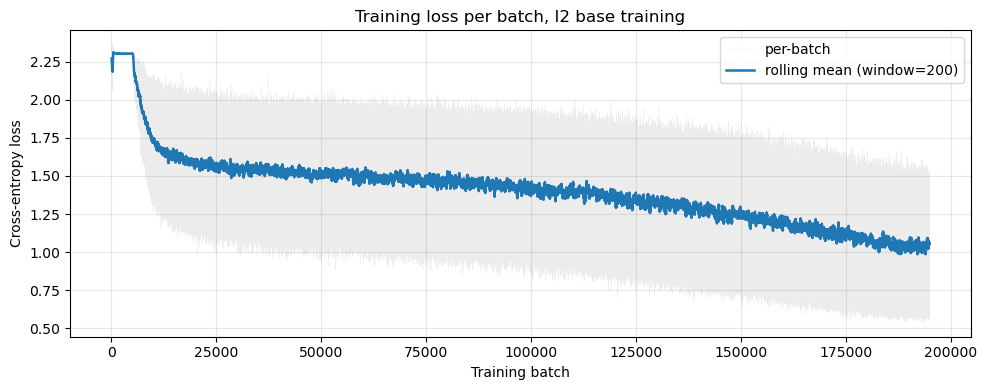

In [14]:
import numpy as np
losses = np.array(winner_base['batch_losses'])
window = 200
kernel = np.ones(window) / window
rolling = np.convolve(losses, kernel, mode='valid')
plt.figure(figsize=(10, 4))
plt.plot(losses, linewidth=0.3, alpha=0.15, color='gray', label='per-batch')
plt.plot(np.arange(len(rolling)) + window // 2, rolling, linewidth=1.8, color='C0',
         label=f'rolling mean (window={window})')
plt.xlabel('Training batch')
plt.ylabel('Cross-entropy loss')
plt.title('Training loss per batch, I2 base training')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('plot_loss_per_batch_base.png', dpi=120)
plt.show()

### Plot 2. Train and test accuracy per epoch

Training accuracy is measured on the augmented training batches (with CutMix and MixUp), so it stays far below the test accuracy. Test accuracy is shown for the raw weights and for the EMA weights.


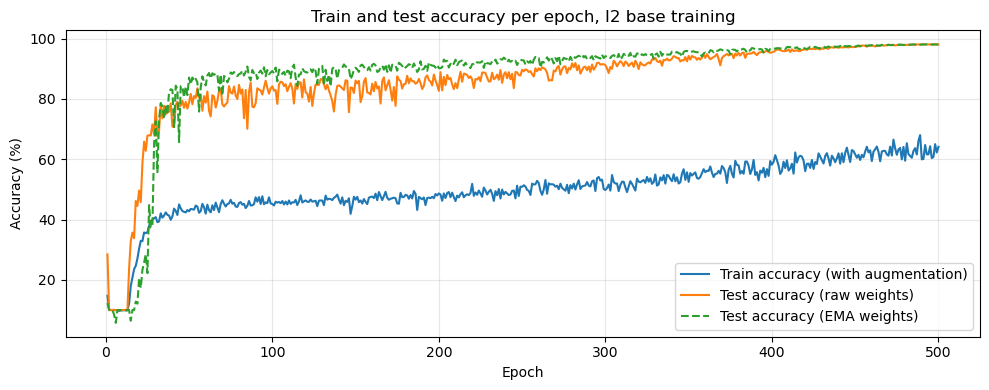

In [15]:
plt.figure(figsize=(10, 4))
epochs = np.arange(1, len(winner_base['train_accs']) + 1)
plt.plot(epochs, [a*100 for a in winner_base['train_accs']], label='Train accuracy (with augmentation)')
plt.plot(epochs, [a*100 for a in winner_base['test_accs']],  label='Test accuracy (raw weights)')
plt.plot(epochs, [a*100 for a in winner_base['test_accs_ema']], label='Test accuracy (EMA weights)', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Train and test accuracy per epoch, I2 base training')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('plot_accuracy_per_epoch_base.png', dpi=120)
plt.show()

### 10b. After the SAM+SWA fine-tune

After the 500-epoch base training above, the I2 model was trained for 150 more epochs with Sharpness-Aware Minimisation (SAM, Foret et al., ICLR 2021) and Stochastic Weight Averaging (SWA, Izmailov et al., UAI 2018). SAM computes each update at slightly perturbed weights (moved a small distance in the direction that increases the loss), which favours flat regions of the loss surface. SWA keeps a running average of the weights from fine-tune epoch 75 onwards. The fine-tune raised the test accuracy from 98.10% to **98.31%** plain (98.35% with flip averaging, Section 11). The kept checkpoint is the EMA weights from the best fine-tune epoch, not the final SWA average.

The loading cell prints 98.29% (EMA) for the same checkpoint. That value was measured during training in 32-bit precision. Section 11 evaluates the same weights with bfloat16 autocast and gets 98.31%. The plots below show the fine-tune on its own. With `LOAD_PRETRAINED=False` this section is skipped.


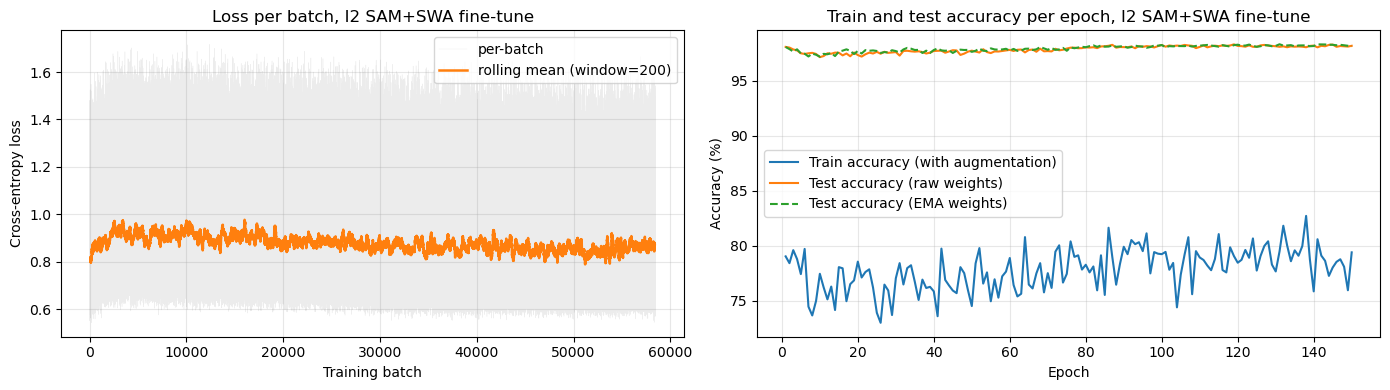


After SAM+SWA fine-tune: best test accuracy = 98.29% (EMA)


In [16]:
if winner_ft is not None:
    import numpy as np
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Left: fine-tune loss per batch with rolling mean
    losses_ft = np.array(winner_ft['batch_losses'])
    window = 200
    kernel = np.ones(window) / window
    rolling_ft = np.convolve(losses_ft, kernel, mode='valid')
    axes[0].plot(losses_ft, linewidth=0.3, alpha=0.15, color='gray', label='per-batch')
    axes[0].plot(np.arange(len(rolling_ft)) + window // 2, rolling_ft,
                 linewidth=1.8, color='C1', label=f'rolling mean (window={window})')
    axes[0].set_xlabel('Training batch')
    axes[0].set_ylabel('Cross-entropy loss')
    axes[0].set_title('Loss per batch, I2 SAM+SWA fine-tune')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Right: fine-tune accuracies per epoch
    eps_ft = np.arange(1, len(winner_ft['train_accs']) + 1)
    axes[1].plot(eps_ft, [a*100 for a in winner_ft['train_accs']],    label='Train accuracy (with augmentation)')
    axes[1].plot(eps_ft, [a*100 for a in winner_ft['test_accs']],     label='Test accuracy (raw weights)')
    axes[1].plot(eps_ft, [a*100 for a in winner_ft['test_accs_ema']], label='Test accuracy (EMA weights)', linestyle='--')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title('Train and test accuracy per epoch, I2 SAM+SWA fine-tune')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('plot_fine_tune.png', dpi=120)
    plt.show()

    print(f'\nAfter SAM+SWA fine-tune: best test accuracy = {winner_ft["best_acc"]*100:.2f}% '
          f'({"EMA" if winner_ft["best_is_ema"] else "raw"})')
else:
    print('Fine-tune section skipped (LOAD_PRETRAINED=False).')

## 11. Final evaluation of the best single model with flip averaging

Test-time augmentation (TTA) with horizontal flips: the model scores each test image and its mirror image, and the two sets of logits are added before taking the class with the highest score. For this model it changes the test accuracy from 98.31% to 98.35%.


In [17]:
winner_model = SKNet(winner['cfg']).to(device)
winner_model.load_state_dict(winner['best_state'])

acc_plain = evaluate(winner_model, test_loader)
acc_tta   = evaluate_tta(winner_model, test_loader)
print(f'Best single model ({winner["name"]}):')
print(f'  Plain test accuracy   : {acc_plain*100:.2f}%')
print(f'  + flip-TTA            : {acc_tta*100:.2f}%')

/tmp/ipykernel_10156/3951106494.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp and torch.cuda.is_available(),
/tmp/ipykernel_10156/3951106494.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available(),


Best single model (I2_mixup_cutmix):
  Plain test accuracy   : 98.31%
  + flip-TTA            : 98.35%


## 12. Basic mode

Setting `basic_mode=True` in any `SKNetConfig` turns the network into the plain block sequence with L=2 branches `[3×3, 1×1]`, no intra-transitions and no skip connections (see `test_basic_mode()` in Section 8).


## 13. Ensemble of four models

With `LOAD_PRETRAINED_ENSEMBLE = True` (the default) this cell downloads the four ensemble checkpoints, evaluates each model on the test set with and without flip averaging, and then evaluates the ensemble, which averages the softmax outputs of the four models. Here flip averaging averages the softmax outputs for the image and its mirror image, so the single-model numbers can differ slightly from Section 11, which adds logits.

The four models come from two architecture families: two with the wider 14-block layout with intra-transitions (`ft_I2` and `I1_historical`) and two with configuration 1.1, 27 blocks in a row (`ft_g0` and `ft_1_1`, trained with two different base recipes). The prefix `ft_` marks SAM+SWA fine-tuned weights. `I1_historical` is the I1 base checkpoint without fine-tuning. An SWA-only fine-tune of I1 (DropPath kept on and no SAM, because SAM and DropPath do not combine in this code) reached 97.97% against 97.99% for the base, so the base was kept. For I2 the fine-tune helped (+0.21 points plain), so `ft_I2` is used. The members were chosen for high test accuracy and for coming from two different architectures.

The ensemble numbers (98.42% plain, 98.37% with flip averaging) need `LOAD_PRETRAINED_ENSEMBLE = True`. With `False` the cell retrains the four base models with the recipes of the published checkpoints (500 epochs each) but not their SAM+SWA fine-tunes, so it does not reproduce the ensemble numbers.


In [18]:
LOAD_PRETRAINED_ENSEMBLE = True   # True (default): download the 4 ensemble checkpoints. False: retrain the base models only (no SAM+SWA fine-tune), which will not match the ensemble numbers.

import urllib.request, os
import torch.nn.functional as F

# Checkpoint loading shim (same as in Section 9).
import sys, types as _types
if 'sknet_lib' not in sys.modules:
    _sl = _types.ModuleType('sknet_lib')
    for _name in ['SKNetConfig', 'SKNet', 'IntermediateBlock', 'IntraTransition',
                  'StageTransition', 'Cutout', 'EMA', 'SAM']:
        if _name in globals():
            setattr(_sl, _name, globals()[_name])
    sys.modules['sknet_lib'] = _sl

ENSEMBLE_FILES = {
    'ft_g0':         ('ft_g0_ckpt.pt',         '1.1'),
    'ft_1_1':        ('ft_1_1_ckpt.pt',        '1.1'),
    'I1_historical': ('I1_historical_ckpt.pt', 'I1'),
    'ft_I2':         ('ft_I2_ckpt.pt',         'I2'),
}

if LOAD_PRETRAINED_ENSEMBLE:
    try:
        for fname, _ in ENSEMBLE_FILES.values():
            if not os.path.exists(fname):
                print(f'Downloading {fname} ...')
                urllib.request.urlretrieve(URL_BASE + fname, fname)

        pm_probs_plain, pm_probs_flip, labels = [], [], None
        for display_name, (fname, _key) in ENSEMBLE_FILES.items():
            ck = torch.load(fname, weights_only=False, map_location=device)
            model = SKNet(ck['cfg']).to(device).eval()
            model.load_state_dict(ck['state_dict'])
            probs_plain_chunks, probs_flip_chunks, labels_chunks = [], [], []
            with torch.no_grad():
                for x, y in test_loader:
                    x = x.to(device, non_blocking=True)
                    y = y.to(device, non_blocking=True)
                    with torch.cuda.amp.autocast(enabled=torch.cuda.is_available(),
                                                 dtype=torch.bfloat16):
                        l1 = model(x).float()
                        l2 = model(torch.flip(x, dims=[3])).float()
                    p1 = F.softmax(l1, dim=1)
                    p2 = F.softmax(l2, dim=1)
                    probs_plain_chunks.append(p1.cpu())
                    probs_flip_chunks.append(((p1 + p2) / 2).cpu())
                    labels_chunks.append(y.cpu())
            probs_plain = torch.cat(probs_plain_chunks, 0)
            probs_flip  = torch.cat(probs_flip_chunks, 0)
            labels      = torch.cat(labels_chunks, 0)
            acc_plain = (probs_plain.argmax(1) == labels).float().mean().item()
            acc_flip  = (probs_flip.argmax(1)  == labels).float().mean().item()
            print(f'  {display_name:<14} plain={acc_plain*100:.2f}%  +flip={acc_flip*100:.2f}%')
            pm_probs_plain.append(probs_plain)
            pm_probs_flip.append(probs_flip)
            del model
            torch.cuda.empty_cache()

        ens_probs_flip  = torch.stack(pm_probs_flip,  dim=0).mean(0)
        ens_probs_plain = torch.stack(pm_probs_plain, dim=0).mean(0)
        ens_acc_flip  = (ens_probs_flip.argmax(1)  == labels).float().mean().item()
        ens_acc_plain = (ens_probs_plain.argmax(1) == labels).float().mean().item()
        print(f'\nEnsemble of {len(ENSEMBLE_FILES)} models (softmax mean):')
        print(f'  plain        : {ens_acc_plain*100:.2f}%')
        print(f'  + flip TTA   : {ens_acc_flip*100:.2f}%')
    except Exception as e:
        print(f'Ensemble cell skipped (checkpoints unavailable): {e}')
else:
    # The base recipes of the published checkpoints (logs/base_*.log), 500 epochs each, about 4.5 to 5.5 hours per model
    # on one RTX 5090. The SAM+SWA fine-tunes are not repeated here, so the result will not match the ensemble
    # numbers (98.42% plain, 98.37% with flip averaging).
    NUM_EPOCHS = 500
    ENSEMBLE_RECIPES = {
        'ft_g0':         ('1.1', dict(warmup_epochs=25, mixup_prob=0.5)),
        'ft_1_1':        ('1.1', dict(warmup_epochs=5)),
        'I1_historical': ('I1',  dict(warmup_epochs=5)),
        'ft_I2':         ('I2',  dict(warmup_epochs=5, mixup_prob=0.5)),
    }
    print(f'Retraining {len(ENSEMBLE_RECIPES)} ensemble bases (NUM_EPOCHS={NUM_EPOCHS} each).')
    print('The SAM+SWA fine-tunes are not repeated in this branch.')
    for name, (cfg_key, extra) in ENSEMBLE_RECIPES.items():
        print(f'\n--- Training {name} (config={cfg_key}) ---')
        _ = train_one_config(RUN_CONFIGS[cfg_key], num_epochs=NUM_EPOCHS, **extra)
        torch.cuda.empty_cache()
    print('\nRetraining of the base models complete. The ensemble accuracy is not recomputed in this branch.')

/tmp/ipykernel_10156/388190810.py:40: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available(),


  ft_g0          plain=98.26%  +flip=98.25%
  ft_1_1         plain=97.96%  +flip=98.05%
  I1_historical  plain=97.99%  +flip=98.09%
  ft_I2          plain=98.31%  +flip=98.36%

Ensemble of 4 models (softmax mean):
  plain        : 98.42%
  + flip TTA   : 98.37%
